In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
disease_df = pd.read_csv("data/Diseases_and_Symptoms_dataset.csv" , low_memory=False)
desc_df = pd.read_csv("data/description.csv")
med_df = pd.read_csv("data/medications.csv" , low_memory=False)
prec_df = pd.read_csv("data/precautions.csv" , low_memory=False)
workout_df = pd.read_csv("data/workout.csv" , low_memory=False)
diet_df = pd.read_csv("data/diets.csv" , low_memory=False)

## Disease - Symptom

In [3]:
disease_df.shape

(96088, 231)

In [4]:
disease_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96088 entries, 0 to 96087
Columns: 231 entries, diseases to low urine output
dtypes: int64(230), str(1)
memory usage: 170.9 MB


In [5]:
disease_df.head()

,diseases,anxiety and nervousness,depression,shortness of breath,depressive or psychotic symptoms,sharp chest pain,dizziness,insomnia,abnormal involuntary movements,chest tightness,...,sneezing,leg weakness,hysterical behavior,arm lump or mass,bleeding gums,pain in gums,diaper rash,hesitancy,back stiffness or tightness,low urine output
0,panic disorder,1,0,1,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,panic disorder,0,0,1,1,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,panic disorder,1,1,1,1,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,panic disorder,1,0,0,1,0,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
4,panic disorder,1,1,0,0,0,0,1,1,1,...,0,0,0,0,0,0,0,0,0,0


In [6]:
disease_df.columns

Index(['diseases', 'anxiety and nervousness', 'depression',
       'shortness of breath', 'depressive or psychotic symptoms',
       'sharp chest pain', 'dizziness', 'insomnia',
       'abnormal involuntary movements', 'chest tightness',
       ...
       'sneezing', 'leg weakness', 'hysterical behavior', 'arm lump or mass',
       'bleeding gums', 'pain in gums', 'diaper rash', 'hesitancy',
       'back stiffness or tightness', 'low urine output'],
      dtype='str', length=231)

In [7]:
disease_df.isnull().sum().sort_values(ascending=False).head(20)

diseases                            0
anxiety and nervousness             0
depression                          0
shortness of breath                 0
depressive or psychotic symptoms    0
sharp chest pain                    0
dizziness                           0
insomnia                            0
abnormal involuntary movements      0
chest tightness                     0
palpitations                        0
irregular heartbeat                 0
breathing fast                      0
hoarse voice                        0
sore throat                         0
difficulty speaking                 0
cough                               0
nasal congestion                    0
throat swelling                     0
diminished hearing                  0
dtype: int64

In [8]:
disease_df.duplicated().sum()

np.int64(0)

In [9]:
disease_df = disease_df.drop_duplicates()

### Disease Distribution

In [10]:
disease_df["diseases"].value_counts().head(15)

diseases
cystitis                          1219
vulvodynia                        1218
nose disorder                     1218
complex regional pain syndrome    1217
spondylosis                       1216
hypoglycemia                      1215
conjunctivitis due to allergy     1215
vaginal cyst                      1215
esophagitis                       1215
peripheral nerve disorder         1215
gastrointestinal hemorrhage       1214
diverticulitis                    1214
acute bronchitis                  1213
infectious gastroenteritis        1212
pneumonia                         1212
Name: count, dtype: int64

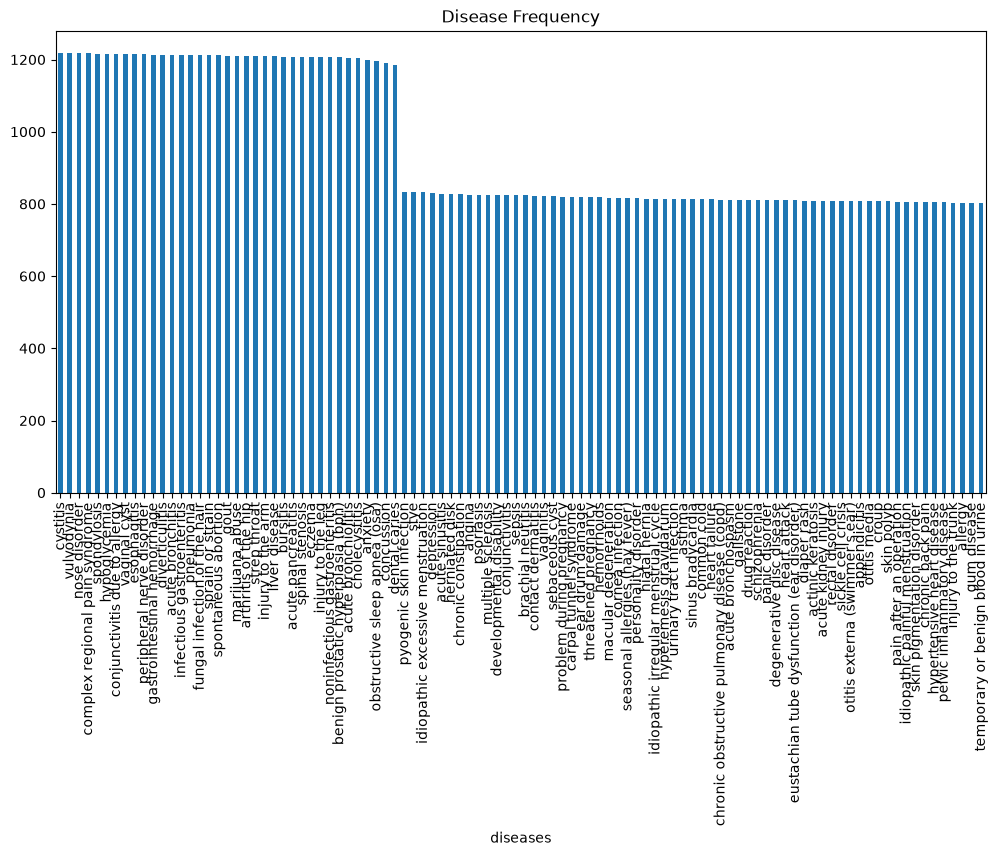

In [11]:
plt.figure(figsize=(12,6))
disease_df["diseases"].value_counts().plot(kind="bar")
plt.title("Disease Frequency")
plt.xticks(rotation=90)
plt.show()

### Number of Symptoms per Patient

In [12]:
symptom_cols = disease_df.columns.drop("diseases")

disease_df = disease_df.assign(
    Symptom_Count=disease_df[symptom_cols].sum(axis=1)
).copy()

C:\Users\shiva\AppData\Local\Temp\ipykernel_15908\874603016.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  disease_df = disease_df.assign(


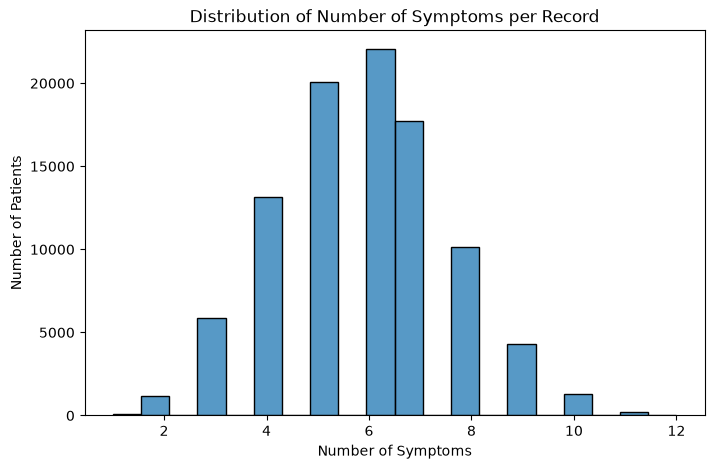

In [13]:
# ---How many symptoms does a typical patient record have---
plt.figure(figsize=(8,5))
sns.histplot(disease_df["Symptom_Count"], bins=20)
plt.title("Distribution of Number of Symptoms per Record")
plt.xlabel("Number of Symptoms")
plt.ylabel("Number of Patients")
plt.show()

In [14]:
common_symptoms = disease_df[symptom_cols].sum().sort_values(ascending=False)

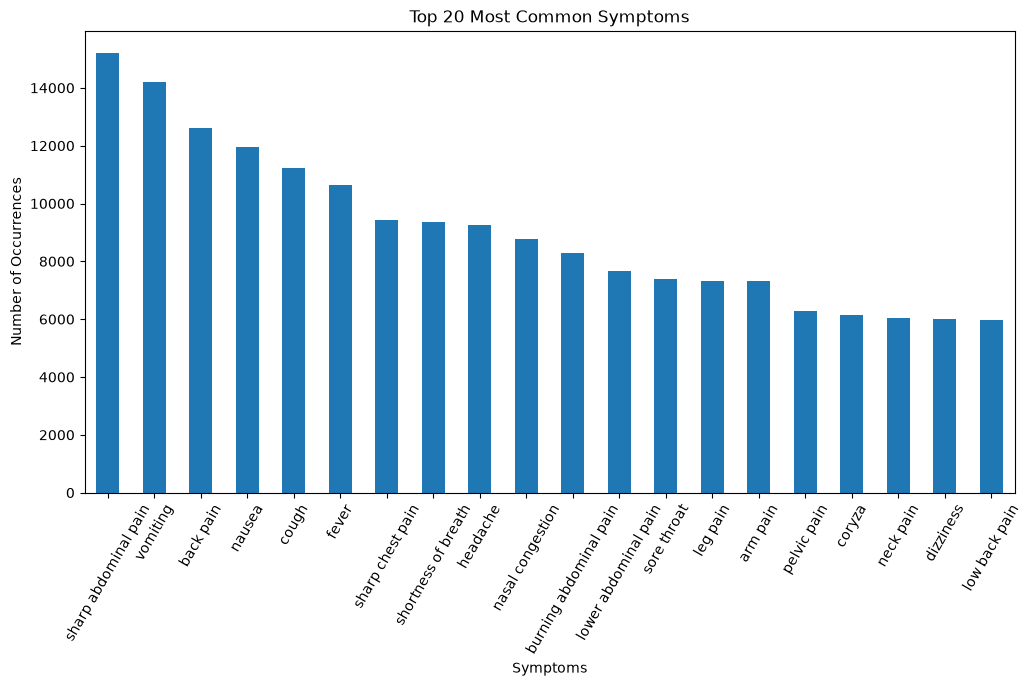

In [15]:
# ---Number of times each symptom appears in the whole dataset---
plt.figure(figsize=(12,6))
common_symptoms.head(20).plot(kind="bar")
plt.title("Top 20 Most Common Symptoms")
plt.xlabel("Symptoms")
plt.ylabel("Number of Occurrences")
plt.xticks(rotation=60)
plt.show()

In [16]:
corr = disease_df[symptom_cols].corr().abs()

pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack()
        .sort_values(ascending=False)
        .head(20)
)

In [17]:
pairs

regurgitation                regurgitation.1                 0.645223
pain during intercourse      vaginal redness                 0.572854
mouth ulcer                  bleeding gums                   0.569388
back cramps or spasms        back stiffness or tightness     0.564305
pus draining from ear        bleeding from ear               0.559874
mass on eyelid               eyelid lesion or rash           0.533551
eyelid swelling              eyelid lesion or rash           0.531252
pain in testicles            symptoms of prostate            0.527938
abnormal movement of eyelid  blindness                       0.522507
arm swelling                 elbow swelling                  0.519979
pain in testicles            impotence                       0.518855
swelling of scrotum          pain in testicles               0.518497
back mass or lump            arm lump or mass                0.514584
neck swelling                mouth pain                      0.514550
lack of growth      

In [18]:
# ---corr() computes the Pearson correlation between every pair of symptom columns---
# ---Think of it as comparing columns, not rows---
corr

,anxiety and nervousness,depression,shortness of breath,depressive or psychotic symptoms,sharp chest pain,dizziness,insomnia,abnormal involuntary movements,chest tightness,palpitations,...,sneezing,leg weakness,hysterical behavior,arm lump or mass,bleeding gums,pain in gums,diaper rash,hesitancy,back stiffness or tightness,low urine output
anxiety and nervousness,1.000000,0.483893,0.045798,0.413263,0.006704,0.012393,0.369112,0.120410,0.022084,0.158951,...,0.018128,0.021672,0.174254,0.011200,0.011242,0.017676,0.011531,0.013675,0.011312,0.013755
depression,0.483893,1.000000,0.045637,0.418977,0.009981,0.008314,0.370916,0.121205,0.020596,0.151999,...,0.018418,0.022018,0.192476,0.011379,0.011422,0.017958,0.011715,0.013893,0.011492,0.013975
shortness of breath,0.045798,0.045637,1.000000,0.032990,0.254026,0.057654,0.129714,0.073223,0.284071,0.227691,...,0.034499,0.041243,0.021945,0.021315,0.021395,0.033638,0.021945,0.026024,0.021527,0.026176
depressive or psychotic symptoms,0.413263,0.418977,0.032990,1.000000,0.010748,0.069362,0.314867,0.185992,0.023226,0.144935,...,0.021716,0.025961,0.160598,0.013417,0.013467,0.021174,0.013813,0.016381,0.013550,0.016477
sharp chest pain,0.006704,0.009981,0.254026,0.010748,1.000000,0.028882,0.035044,0.012089,0.268738,0.191679,...,0.034635,0.041406,0.022031,0.021399,0.021479,0.033771,0.022031,0.026126,0.021612,0.026280
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
pain in gums,0.017676,0.017958,0.033638,0.021174,0.033771,0.026448,0.019558,0.021255,0.022336,0.017400,...,0.010731,0.012829,0.006826,0.006630,0.304369,1.000000,0.006826,0.008095,0.006696,0.008142
diaper rash,0.011531,0.011715,0.021945,0.013813,0.022031,0.017254,0.012759,0.013866,0.014572,0.011351,...,0.007001,0.008369,0.004453,0.004325,0.004342,0.006826,1.000000,0.005281,0.004368,0.005312
hesitancy,0.013675,0.013893,0.026024,0.016381,0.026126,0.020461,0.015131,0.016443,0.017280,0.013461,...,0.008302,0.009925,0.005281,0.005129,0.005149,0.008095,0.005281,1.000000,0.005180,0.492258
back stiffness or tightness,0.011312,0.011492,0.021527,0.013550,0.021612,0.016925,0.012517,0.013602,0.014294,0.011135,...,0.006867,0.008210,0.004368,0.004243,0.004259,0.006696,0.004368,0.005180,1.000000,0.005211


In [19]:
# ---Calculate percentage of positive values---
# ---Most symptom columns are sparse, meaning only a small percentage of patients exhibit each symptom---
(disease_df[symptom_cols].mean()*100).sort_values(ascending=False)

sharp abdominal pain    15.836525
vomiting                14.784364
back pain               13.142120
nausea                  12.428191
cough                   11.676796
                          ...    
recent pregnancy         0.420448
arm lump or mass         0.418366
infertility              0.415244
throat swelling          0.410041
bleeding from ear        0.409000
Length: 230, dtype: float64

## Disease - Description

In [20]:
desc_df["Length"] = desc_df["Description"].str.len()

In [21]:
desc_df

,Disease,Description,Length
0,Panic disorder,Panic disorder is a mental health condition ma...,232
1,Vaginitis,Vaginitis is inflammation of the vaginal tissu...,217
2,Problem during pregnancy,Problems during pregnancy refer to medical com...,195
3,Acute pancreatitis,Acute pancreatitis is a sudden inflammation of...,185
4,Asthma,Asthma is a chronic inflammatory disease of th...,183
...,...,...,...
95,Heart failure,Heart failure is a condition where the heart c...,163
96,Conjunctivitis,Conjunctivitis (pink eye) is inflammation of t...,153
97,Herniated disk,A herniated disk occurs when the inner gel-lik...,168
98,Diaper rash,Diaper rash is skin irritation in the diaper a...,135


In [22]:
desc_df.isnull().sum()

Disease        0
Description    0
Length         0
dtype: int64

In [23]:
desc_df.duplicated().sum()

np.int64(0)

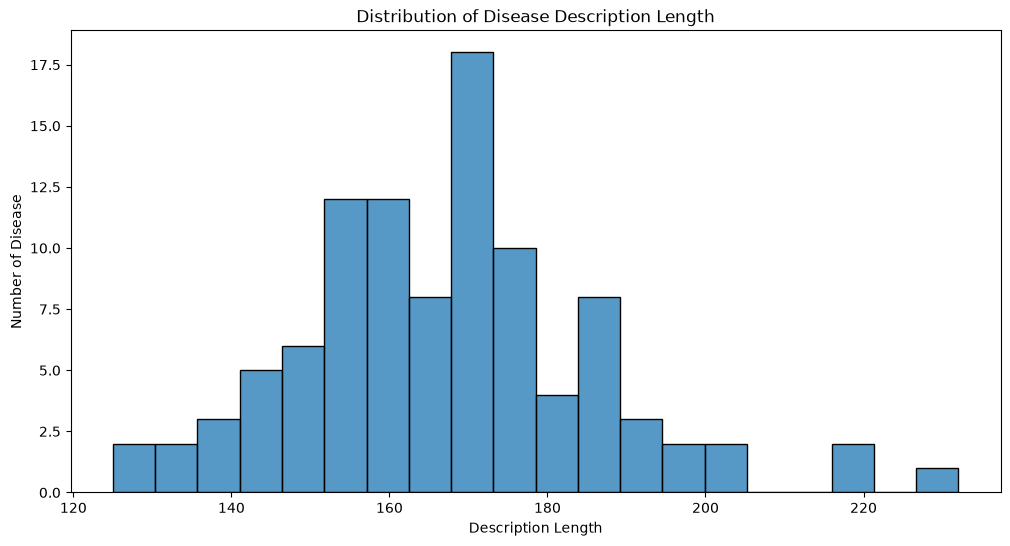

In [24]:
plt.figure(figsize = (12,6))
sns.histplot(desc_df["Length"] , bins = 20)
plt.title("Distribution of Disease Description Length")
plt.xlabel("Description Length")
plt.ylabel("Number of Disease")
plt.show()

## Medication

In [25]:
med_df.isnull().sum()

Disease       0
Medication    0
dtype: int64

In [26]:
med_df.duplicated().sum()

np.int64(0)

In [27]:
# ---medications class earlier was str which is resulting in counting characters---
print(type(med_df["Medication"].iloc[0]))
print(med_df["Medication"].iloc[0])

<class 'str'>
['SSRIs (e.g., Sertraline, Fluoxetine)', 'Benzodiazepines (e.g., Clonazepam, Alprazolam)', 'SNRIs (e.g., Venlafaxine)', 'Beta-blockers', 'Cognitive Behavioral Therapy (CBT)']


In [28]:
# ---To count medicines medication must be list---
import ast

# Convert strings to lists
med_df["Medication"] = med_df["Medication"].apply(ast.literal_eval)

# Count medicines
med_df["Medicine_Count"] = med_df["Medication"].str.len()

med_df["Medicine_Count"].value_counts()

Medicine_Count
5    100
Name: count, dtype: int64

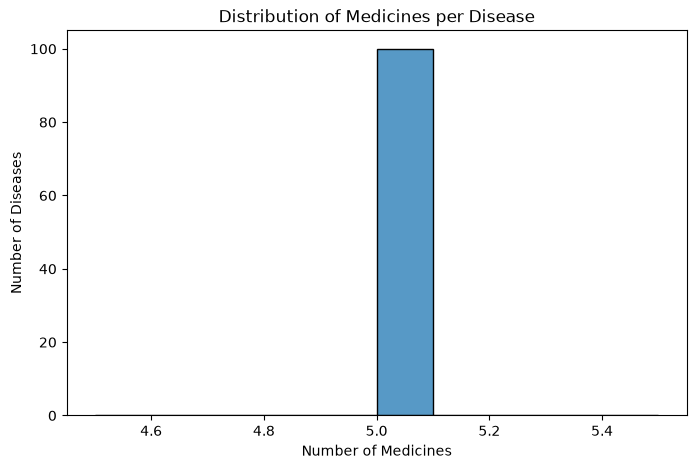

In [29]:
# ---Medications per Diseases---
med_df["Medicine_Count"] = med_df["Medication"].str.len()

plt.figure(figsize=(8,5))
sns.histplot(med_df["Medicine_Count"], bins=10)
plt.title("Distribution of Medicines per Disease")
plt.xlabel("Number of Medicines")
plt.ylabel("Number of Diseases")
plt.show()

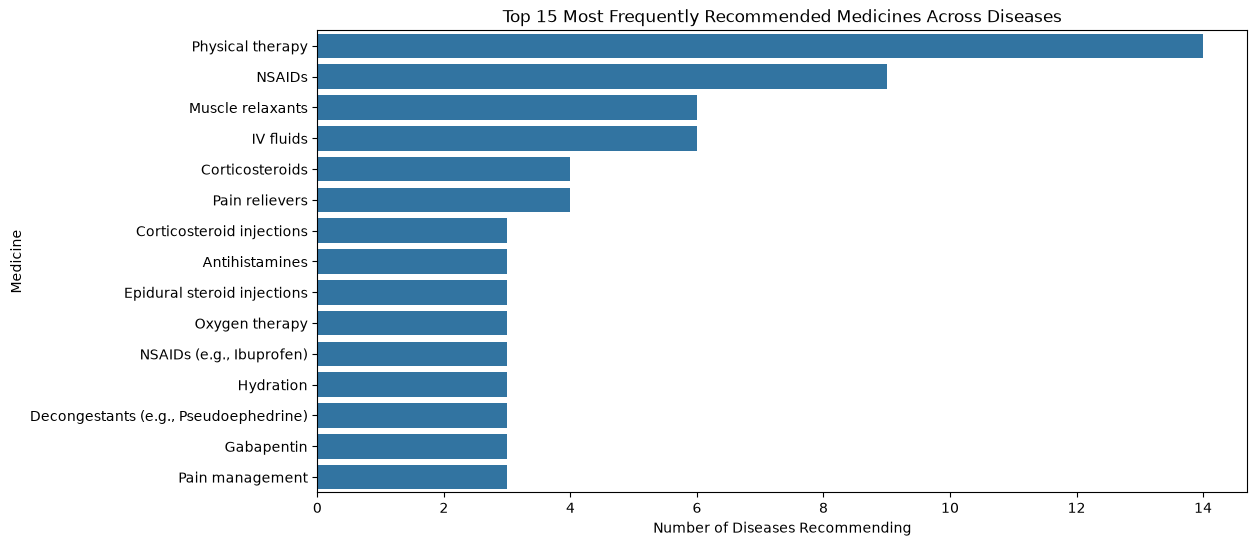

In [30]:
# ---Count how many diseases recommend each medicine---
from collections import Counter
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Flatten all medicine lists
all_medicines = [med for meds in med_df["Medication"] for med in meds]

# Count frequency
medicine_counts = Counter(all_medicines)

# Convert to DataFrame
top_med_df = (
    pd.DataFrame(medicine_counts.items(), columns=["Medicine", "Count"])
      .sort_values("Count", ascending=False)
      .head(15)
)

# Plot
plt.figure(figsize=(12,6))
sns.barplot(data=top_med_df, x="Count", y="Medicine")
plt.title("Top 15 Most Frequently Recommended Medicines Across Diseases")
plt.xlabel("Number of Diseases Recommending")
plt.ylabel("Medicine")
plt.show()





### Display medicines for a specific disease

In [31]:
med_df.loc[med_df["Disease"] == "Panic disorder", "Medication"].iloc[0]

['SSRIs (e.g., Sertraline, Fluoxetine)',
 'Benzodiazepines (e.g., Clonazepam, Alprazolam)',
 'SNRIs (e.g., Venlafaxine)',
 'Beta-blockers',
 'Cognitive Behavioral Therapy (CBT)']

# Disease - Precautions

In [32]:
prec_df.shape

(100, 5)

In [33]:
prec_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Disease       100 non-null    str  
 1   Precaution_1  100 non-null    str  
 2   Precaution_2  100 non-null    str  
 3   Precaution_3  100 non-null    str  
 4   Precaution_4  100 non-null    str  
dtypes: str(5)
memory usage: 14.3 KB


In [34]:
prec_df.isnull().sum()

Disease         0
Precaution_1    0
Precaution_2    0
Precaution_3    0
Precaution_4    0
dtype: int64

In [35]:
prec_df.duplicated().sum()

np.int64(0)

In [36]:
precaution_cols = [c for c in prec_df.columns if c.startswith("Precaution")]

prec_df["Precaution_Count"] = prec_df[precaution_cols].notna().sum(axis=1)
prec_df["Precaution_Count"].value_counts()

Precaution_Count
4    100
Name: count, dtype: int64

# Disease - Workouts

In [38]:
workout_df.shape

(100, 2)

In [39]:
workout_df.isnull().sum()

Disease     0
Workouts    0
dtype: int64

In [40]:
workout_df.duplicated().sum()

np.int64(0)

In [41]:
# ---As the type is str---
print(type(workout_df["Workouts"].iloc[0]))
print(workout_df["Workouts"].iloc[0])

<class 'str'>
["Deep breathing exercises: Calm your mind by focusing on slow, deep breaths", "Yoga: Combines breathing and movement for relaxation", "Mindfulness meditation: Helps reduce anxiety by staying present", "Regular aerobic exercise: Boosts mood and reduces stress"]


In [42]:
# ---Converting string into list---
import ast

workout_df["Workouts"] = workout_df["Workouts"].apply(ast.literal_eval)

In [43]:
# Number of Workout per Disease
workout_df["Workout_count"] = workout_df["Workouts"].str.len()
workout_df["Workout_count"].value_counts()

Workout_count
4    100
Name: count, dtype: int64

# Disease - Diets

In [44]:
diet_df.shape

(100, 2)

In [45]:
diet_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Disease  100 non-null    str  
 1   Diet     100 non-null    str  
dtypes: str(2)
memory usage: 21.4 KB


In [46]:
diet_df.duplicated().sum()

np.int64(0)

In [47]:
diet_df.isnull().sum()

Disease    0
Diet       0
dtype: int64

In [57]:
print(type(diet_df["Diet"].iloc[0]))
print(diet_df["Diet"].iloc[0])

<class 'str'>
['Magnesium-rich foods (spinach, pumpkin seeds, almonds)', 'Omega-3 fatty acids (salmon, flaxseeds, walnuts)', 'Complex carbs (oats, quinoa)', 'Green tea (L-theanine)', 'Limit caffeine and sugar']


In [58]:
import ast

diet_df["Diet_List"] = diet_df["Diet"].apply(ast.literal_eval)

In [59]:
diet_df["Diet_Count"] = diet_df["Diet_List"].str.len()
diet_df["Diet_Count"].value_counts()

Diet_Count
5    96
4     4
Name: count, dtype: int64

In [60]:
from collections import Counter

all_diets = [
    diet.strip()
    for diets in diet_df["Diet_List"]
    for diet in diets
]

diet_counts = Counter(all_diets).most_common(15)

In [61]:
top_diet_df = pd.DataFrame(diet_counts, columns=["Diet", "Count"])

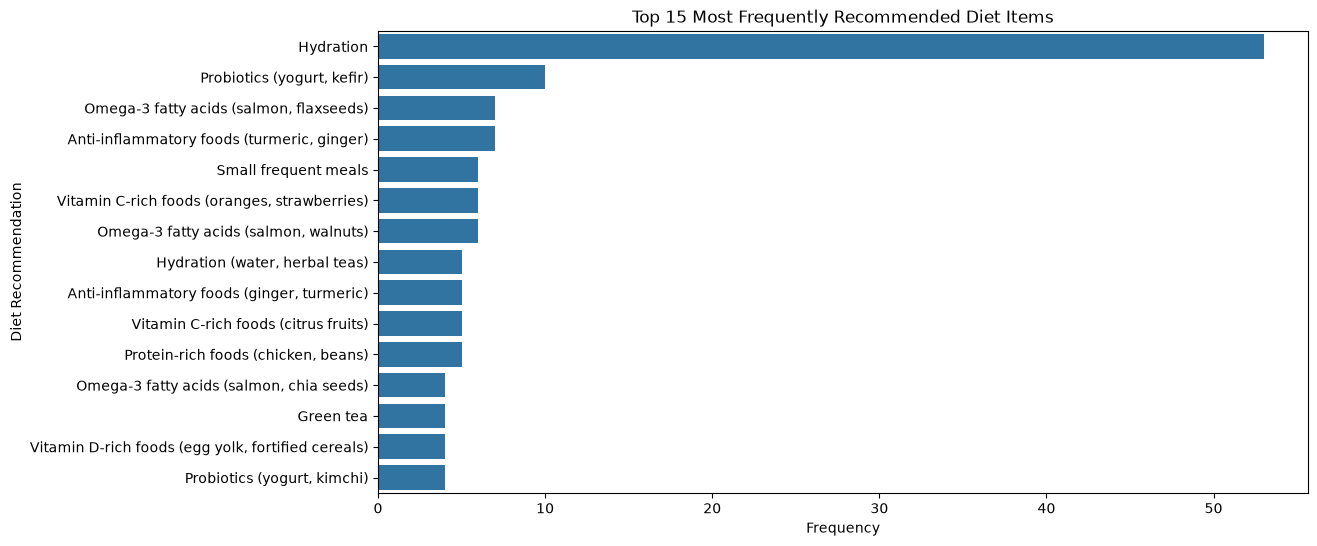

In [54]:
plt.figure(figsize=(12,6))
sns.barplot(data=top_diet_df, x="Count", y="Diet")

plt.title("Top 15 Most Frequently Recommended Diet Items")
plt.xlabel("Frequency")
plt.ylabel("Diet Recommendation")
plt.show()

### preprocessing needs to be done 

In [62]:
datasets = {
    "Description": desc_df,
    "Medication": med_df,
    "Precautions": prec_df,
    "Workout": workout_df,
    "Diet": diet_df
}

for name, data in datasets.items():
    missing = set(disease_df["diseases"]) - set(data["Disease"])
    print(f"{name}: {len(missing)} missing diseases")

Description: 100 missing diseases
Medication: 99 missing diseases
Precautions: 100 missing diseases
Workout: 100 missing diseases
Diet: 100 missing diseases


In [64]:
print(disease_df["diseases"].head())

0    panic disorder
1    panic disorder
2    panic disorder
3    panic disorder
4    panic disorder
Name: diseases, dtype: str


In [65]:
print(desc_df["Disease"].head())

0              Panic disorder
1                   Vaginitis
2    Problem during pregnancy
3          Acute pancreatitis
4                      Asthma
Name: Disease, dtype: str
